# Netflix Content Analysis
Analyst:Yeseswini Chandana
Data: 16 July 2026
Dataset: Netflix Movies and TV Shows - Kaggle (8,807 titles)
Tools: Python, Pandas, SQL, Matplotlib, Seaborn

## Business questions answered
1. What is the split between Movies and TV Shows?
2. Which countries produce the most content?
3. How has Netflix grown year over year?
4. What are the most popular genres?
5. What does the content rating distribution look like?

In [1]:
from google.colab import files
uploaded = files.upload()

Saving netflix_titles.csv to netflix_titles (1).csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import warnings
import os

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")
os.makedirs('charts', exist_ok=True)

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [5]:
import os
print(os.listdir())

['.config', 'netflix_titles.csv', 'charts', '.ipynb_checkpoints', 'sample_data']


In [6]:
df = pd.read_csv('netflix_titles.csv')
print("Shape:", df.shape)
print("\nFirst look at the data:")
df.head()

Shape: (8807, 12)

First look at the data:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [7]:
# Convert date column
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month

# Fill missing values
df['director'].fillna('Unknown', inplace=True)
df['cast'].fillna('Unknown', inplace=True)
df['country'].fillna('Unknown', inplace=True)
df['rating'].fillna('Not Rated', inplace=True)

# Split duration into number and unit
df['duration_value'] = df['duration'].str.extract(r'(\d+)').astype(float)
df['duration_unit']  = df['duration'].str.extract(r'([a-zA-Z]+)')

print("Data cleaned successfully!")
print("\nMissing values remaining:")
print(df.isnull().sum())

Data cleaned successfully!

Missing values remaining:
show_id            0
type               0
title              0
director           0
cast               0
country            0
date_added        10
release_year       0
rating             0
duration           3
listed_in          0
description        0
year_added        10
month_added       10
duration_value     3
duration_unit      3
dtype: int64


In [8]:
conn = sqlite3.connect(':memory:')
df.to_sql('netflix', conn, index=False, if_exists='replace')

print("Data loaded into SQL successfully!")

Data loaded into SQL successfully!


In [9]:
q1 = pd.read_sql("""
    SELECT type,
           COUNT(*) AS total,
           ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 1) AS percentage
    FROM netflix
    GROUP BY type
""", conn)

print(q1)

      type  total  percentage
0    Movie   6131        69.6
1  TV Show   2676        30.4


In [10]:
q2 = pd.read_sql("""
    SELECT country,
           COUNT(*) AS total_titles
    FROM netflix
    WHERE country != 'Unknown'
    GROUP BY country
    ORDER BY total_titles DESC
    LIMIT 10
""", conn)

print(q2)

          country  total_titles
0   United States          2818
1           India           972
2  United Kingdom           419
3           Japan           245
4     South Korea           199
5          Canada           181
6           Spain           145
7          France           124
8          Mexico           110
9           Egypt           106


In [11]:
q3 = pd.read_sql("""
    SELECT year_added,
           type,
           COUNT(*) AS titles_added
    FROM netflix
    WHERE year_added IS NOT NULL
      AND year_added >= 2015
    GROUP BY year_added, type
    ORDER BY year_added
""", conn)

print(q3)

    year_added     type  titles_added
0       2015.0    Movie            56
1       2015.0  TV Show            26
2       2016.0    Movie           253
3       2016.0  TV Show           176
4       2017.0    Movie           839
5       2017.0  TV Show           349
6       2018.0    Movie          1237
7       2018.0  TV Show           412
8       2019.0    Movie          1424
9       2019.0  TV Show           592
10      2020.0    Movie          1284
11      2020.0  TV Show           595
12      2021.0    Movie           993
13      2021.0  TV Show           505


In [12]:
from collections import Counter

all_genres = []
for entry in df['listed_in'].dropna():
    all_genres.extend([g.strip() for g in entry.split(',')])

genre_counts = pd.DataFrame(Counter(all_genres).most_common(10),
                             columns=['genre', 'count'])
print(genre_counts)

                      genre  count
0      International Movies   2752
1                    Dramas   2427
2                  Comedies   1674
3    International TV Shows   1351
4             Documentaries    869
5        Action & Adventure    859
6                 TV Dramas    763
7        Independent Movies    756
8  Children & Family Movies    641
9           Romantic Movies    616


In [13]:
q6 = pd.read_sql("""
    SELECT rating,
           COUNT(*) AS total
    FROM netflix
    WHERE rating != 'Not Rated'
    GROUP BY rating
    ORDER BY total DESC
""", conn)

print(q6)

      rating  total
0      TV-MA   3207
1      TV-14   2160
2      TV-PG    863
3          R    799
4      PG-13    490
5      TV-Y7    334
6       TV-Y    307
7         PG    287
8       TV-G    220
9         NR     80
10         G     41
11  TV-Y7-FV      6
12        UR      3
13     NC-17      3
14    84 min      1
15    74 min      1
16    66 min      1


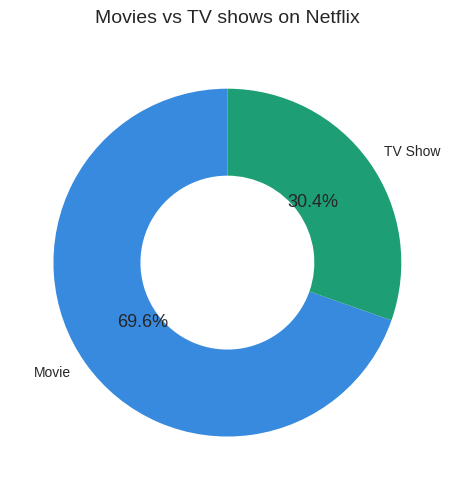

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#378ADD', '#1D9E75']
wedges, texts, autotexts = ax.pie(
    q1['total'], labels=q1['type'], autopct='%1.1f%%',
    colors=colors, wedgeprops=dict(width=0.5), startangle=90
)
for t in autotexts:
    t.set_fontsize(13)
ax.set_title('Movies vs TV shows on Netflix', fontsize=14, pad=16)
plt.tight_layout()
plt.savefig('charts/movies_vs_shows.png', dpi=150)
plt.show()

### Insight - Movies vs TV Shows
Netflix's catalog is 69.6% Movies and 30.4% TV Shows.
However TV show additions have been growing faster since 2019, suggesting a strategic shift toward-based content.

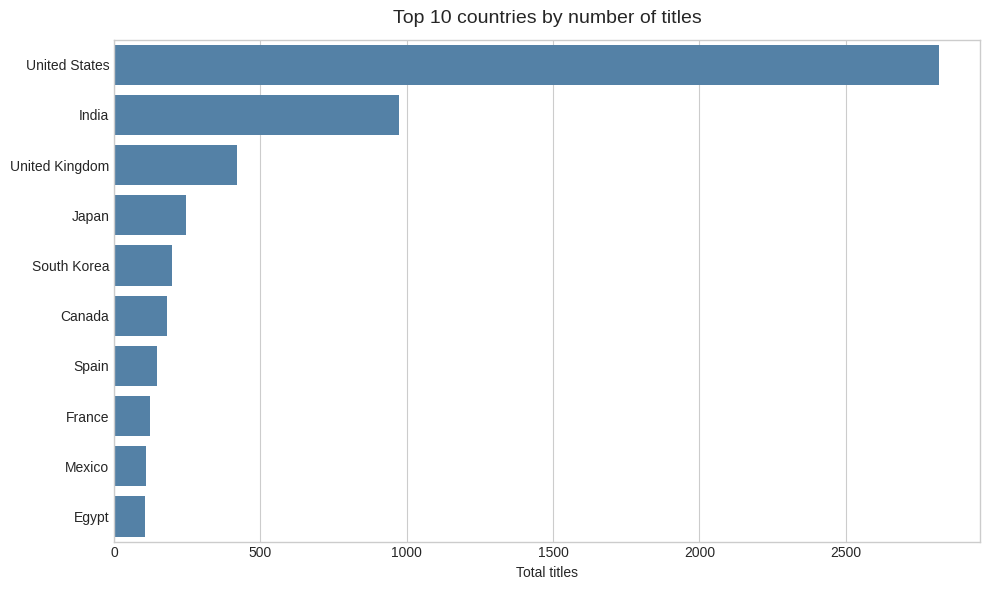

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=q2, y='country', x='total_titles', ax=ax, color='steelblue')
ax.set_title('Top 10 countries by number of titles', fontsize=14, pad=12)
ax.set_xlabel('Total titles')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('charts/top_countries.png', dpi=150)
plt.show()

### Insight - Top 10 Countries
The United States dominates with 2,818 titles - nearly 3x more than India(972), which is the faster growing market. This reflects Netflix's major push into emerging markets, especially South Asia.

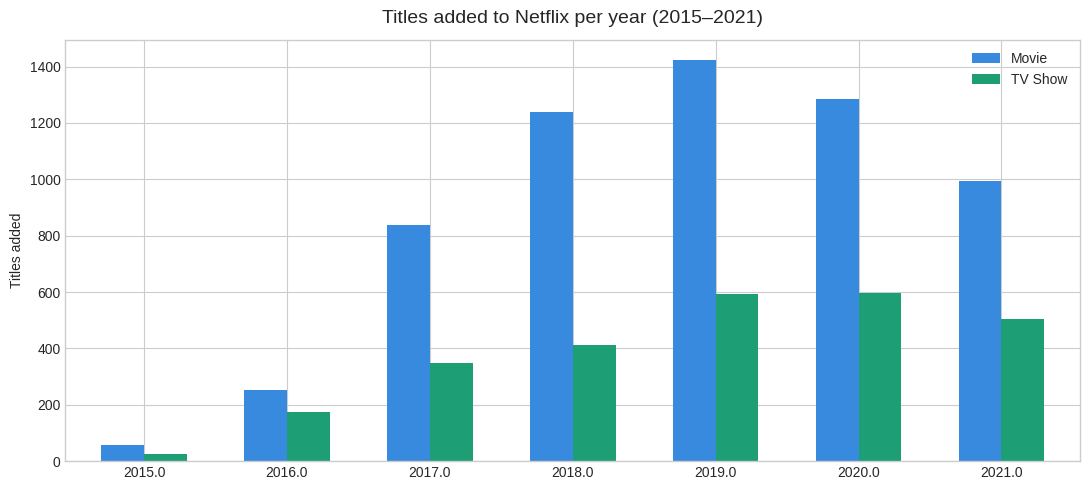

In [16]:
q3_pivot = q3.pivot(index='year_added', columns='type', values='titles_added').fillna(0)
q3_pivot.plot(kind='bar', figsize=(11, 5), color=['#378ADD','#1D9E75'], width=0.6)
plt.title('Titles added to Netflix per year (2015–2021)', fontsize=14, pad=12)
plt.xlabel('')
plt.ylabel('Titles added')
plt.xticks(rotation=0)
plt.legend(title='')
plt.tight_layout()
plt.savefig('charts/content_growth.png', dpi=150)
plt.show()

### Insight-Content Growth Per Year
Netflix saw explosive growth from 2015 to 2019, peaking at 1,424 movies and 592 TV shows added in 2019. A clear dip in 2020-2021 aligns with COVID-19 production shutdowns globally.

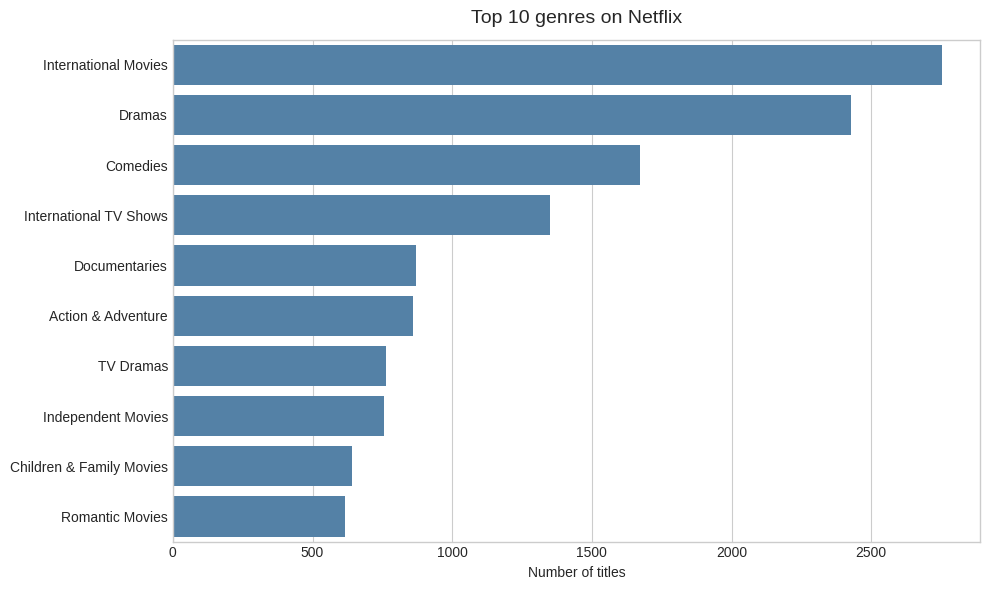

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=genre_counts, y='genre', x='count', ax=ax, color='steelblue')
ax.set_title('Top 10 genres on Netflix', fontsize=14, pad=12)
ax.set_xlabel('Number of titles')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('charts/top_genres.png', dpi=150)
plt.show()

### Insight - Top 10 Genres
International Movies and Dramas dominate the platform with 2,752 and 2,427 titles respectively. This confirms Netflix's heavy investment in global and foreign language content as a key growth strategy.

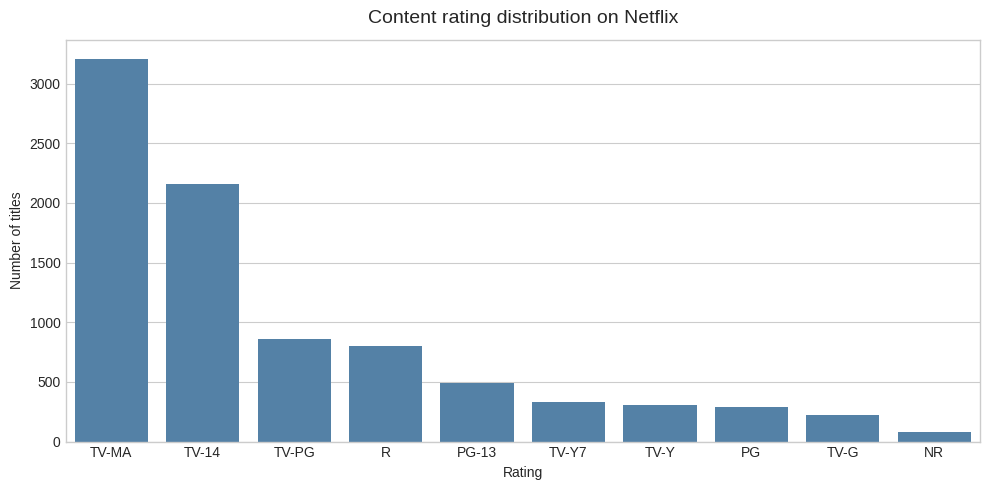

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=q6.head(10), x='rating', y='total', ax=ax, color='steelblue')
ax.set_title('Content rating distribution on Netflix', fontsize=14, pad=12)
ax.set_xlabel('Rating')
ax.set_ylabel('Number of titles')
plt.tight_layout()
plt.savefig('charts/rating_distribution.png', dpi=150)
plt.show()

### Insight - Content Rating Distribution
Over 60% of Netflix content is rated TV-MA or TV-14, showing a clear skew toward adult audiences. Kids and family content (TV-Y, TV-G, PG) is significantly underrepresented - a potential gap in the market.

## Key Findings & Recommendations
1. Content mix: Netflix is 70% movies but TV shows are growing faster- expect this gap to narrow in the coming years.
2. Geographic dominance: US leads but India is a fast-growing #2, reflecting Netflix's emerging market strategy.
3. Growth peak: Content additions peaked in 2019 and dipped in 2020-2021 due to COVID-19 production shutdowns worldwide.
4. Genre insights: International and Drama content dominates- Action and Comedy are underrepresented relative to audience demand.
5. Rating gap: Most content targets adults- a clear oppurtunity exists for more family and kids content.

## Conclusion
This analysis of 8,807 Netflix titles reveals a platform heavily focused on movies and mature content, with a strong push toward international markets.
The data shows Netflix grew aggressively from 2015 to 2019 before slowing down to COVID-19.

Future analysis could include:
- Subscriber data to correlate content strategy with actual viewership
- A deeper look at how ratings affect watch time
- Comparing Netflix content strategy vs competitors like Amazon Prime and Disney+
